# Лабораторна робота №6
## Тема: Машинне навчання з підкріпленням (Reinforcement Learning) та алгоритм Q-Learning
**Дисципліна:** Основи штучного інтелекту  
**Заклад:** Івано-Франківський національний технічний університет нафти і газу (ІФНТУНГ)  
**Посібник:** Копей В. Б., Онисько О. Р. «Основи штучного інтелекту: лабораторний практикум», 2024 р.  
**Студент:** Відоняк Ю. Р., група КІм-25-1, №28 у списку групи $\rightarrow$ **Варіант 4** ($28 - 24 = 4$)  

**Параметри варіанта 4 (Таблиця 3):** $a = 0,\; b = 2,\; c = 3,\; d = 1$  

---

### Мета роботи:
1. Дослідити теоретичні засади навчання з підкріпленням (Reinforcement Learning) на базі марковських процесів прийняття рішень (MDP).
2. Ознайомитися з алгоритмом часової різниці **Q-Learning** та рівнянням оптимальності Белмана.
3. Дослідити та вдосконалити модель Q-агента для дискретної гри **«Камінь-Ножиці-Папір»** (Rock-Paper-Scissors):
   - аналіз наведеного у посібнику спрощеного коду;
   - впровадження канонічного рівняння Белмана та $\varepsilon$-жадібної політики з експоненційним затуханням;
   - експериментальна перевірка адаптивності проти випадкового, зміщеного та циклічного опонентів.
4. **Удосконалити стратегію автономного мобільного робота** (модуль `8_6.py` на базі фізичного рушія PyMunk):
   - формулювання простору станів на основі сенсорного сканування сектора огляду та близькості до меж арени;
   - проектування розширеного простору дій (рух вперед, доворот на ціль $s_1$, маневр ухилення від антиоб'єкта $s_2$, розворот від стіни);
   - побудова системи штрафів і винагород та навчання Q-таблиці в реальному часі;
   - порівняльний аналіз кінематики, траєкторій та результуючого рахунку (Score) між базовою та вдосконаленою стратегіями.


---
## 1. Теоретичні засади алгоритму Q-Learning

Навчання з підкріпленням моделюється як **марковський процес прийняття рішень (MDP)**, який формалізується кортежем:
$$\langle \mathcal{S}, \mathcal{A}, \mathcal{P}, \mathcal{R}, \gamma \rangle$$
- $\mathcal{S}$ — множина станів середовища (State Space);
- $\mathcal{A}$ — множина допустимих дій агента (Action Space);
- $\mathcal{P}(s' \mid s, a)$ — ймовірність переходу зі стану $s$ у стан $s'$ при виконанні дії $a$;
- $\mathcal{R}(s, a, s')$ — функція винагороди (Reward);
- $\gamma \in [0, 1)$ — коефіцієнт дисконтування майбутніх винагород (Discount Factor).

### Рівняння оптимальності Белмана для Q-функції:
Оптимальна функція цінності дії $Q^*(s, a)$ визначає очікувану суму дисконтованих винагород при виборі дії $a$ у стані $s$ з подальшим дотриманням оптимальної стратегії:
$$Q^*(s, a) = \mathcal{R}(s, a) + \gamma \sum_{s' \in \mathcal{S}} \mathcal{P}(s' \mid s, a) \max_{a' \in \mathcal{A}} Q^*(s', a')$$

### Правило оновлення Q-значень (Temporal Difference Learning):
Оскільки агент взаємодіє із середовищем без апріорного знання матриці переходів $\mathcal{P}$ (Model-Free RL), оцінка $Q(s, a)$ ітеративно коригується на величину похибки часової різниці (TD Error $\delta_t$):
$$Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \cdot \underbrace{\left[ r_{t+1} + \gamma \max_{a} Q(s_{t+1}, a) - Q(s_t, a_t) \right]}_{\text{TD-похибка } \delta_t}$$
де:
- $\alpha \in (0, 1]$ — швидкість навчання (Learning Rate);
- $r_{t+1}$ — безпосередня винагорода за перехід;
- $\gamma \max_{a} Q(s_{t+1}, a)$ — дисконтована оцінка максимальної цінності наступного стану.

### Баланс дослідження та експлуатації (Exploration vs. Exploitation):
Для запобігання передчасному сходженню до субоптимальних локальних дій використовується **$\varepsilon$-жадібна стратегія ($\varepsilon$-greedy)** з експоненційним затуханням $\varepsilon$:
$$a_t = \begin{cases} \operatorname{random}(\mathcal{A}), & \text{з ймовірністю } \varepsilon_t \\ \arg\max_{a} Q(s_t, a), & \text{з ймовірністю } 1 - \varepsilon_t \end{cases}$$
$$\varepsilon_{t+1} = \max\left(\varepsilon_{\min},\; \varepsilon_t \cdot d\right), \quad d < 1$$


In [1]:
# Налаштування середовища та бібліотек
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# Забезпечення коректного відображення кирилиці в Matplotlib
matplotlib.rcParams['font.family'] = 'Liberation Sans'
matplotlib.rcParams['axes.unicode_minus'] = False
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Фіксація випадкового зерна для повної відтворюваності експериментів
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Середовище успішно ініціалізовано.")
print(f"NumPy версія: {np.__version__}")
print(f"Matplotlib версія: {matplotlib.__version__}")


Середовище успішно ініціалізовано.
NumPy версія: 2.2.6
Matplotlib версія: 3.10.9


---
## 2. Дослідження та вдосконалення Q-Learning для гри «Камінь-Ножиці-Папір»

У вихідному прикладі методички `lab6.md` наведено наступний спрощений алгоритм:
```python
def update_Q_table(state, action, reward, next_state):
    # Q[state][action] += alpha * (reward + gamma * max(Q[next_state].values()) - Q[state][action])
    Q[state][action] += reward
```
> **Критичний аналіз базового коду:**
> 1. Пряме додавання винагороди `Q[state][action] += reward` без дисконтування $\gamma$ та швидкості навчання $\alpha$ є простою схемою накопичення очок (багаторукий бандит), а не повноцінним Q-навчанням.
> 2. Агент обирає дії виключно випадково (`random.choice(actions)`), не використовуючи поточні оцінки $Q$ для прийняття рішень (відсутня фаза експлуатації).
> 3. Нижче реалізовано повноцінний клас `RPS_QAgent`, що використовує канонічне рівняння Белмана, стани на базі попереднього ходу суперника та $\varepsilon$-greedy політику.


In [2]:
# 1. Повноцінна реалізація Q-агента для гри «Камінь-Ножиці-Папір»
ACTIONS = [0, 1, 2] # 0: Камінь (Rock), 1: Папір (Paper), 2: Ножиці (Scissors)
ACTION_NAMES = ['Камінь', 'Папір', 'Ножиці']

def get_rps_reward(my_act, opp_act):
    """
    Функція винагороди гри «Камінь-Ножиці-Папір»:
    Перемога: +1.0, Нічия: 0.0, Поразка: -1.0
    """
    if my_act == opp_act:
        return 0.0
    # Камінь б'є ножиці (0 б'є 2), Папір б'є камінь (1 б'є 0), Ножиці б'ють папір (2 б'є 1)
    if (my_act == 0 and opp_act == 2) or \
       (my_act == 1 and opp_act == 0) or \
       (my_act == 2 and opp_act == 1):
        return 1.0
    return -1.0

class RPS_QAgent:
    def __init__(self, alpha=0.1, gamma=0.85, eps_start=0.5, eps_min=0.01, eps_decay=0.999):
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = eps_start
        self.eps_min = eps_min
        self.eps_decay = eps_decay
        # Таблиця Q[state, action]: 3 попередні стани (хід суперника) x 3 дії агента
        self.Q = np.zeros((3, 3))
        
    def choose_action(self, state):
        if random.random() < self.epsilon:
            return random.choice(ACTIONS)
        return int(np.argmax(self.Q[state]))
        
    def learn(self, state, action, reward, next_state):
        # Канонічне рівняння Белмана
        best_next = np.max(self.Q[next_state])
        td_target = reward + self.gamma * best_next
        td_error = td_target - self.Q[state, action]
        self.Q[state, action] += self.alpha * td_error
        
        # Експоненційне затухання коефіцієнта дослідження
        self.epsilon = max(self.eps_min, self.epsilon * self.eps_decay)

print("Клас RPS_QAgent успішно створено.")


Клас RPS_QAgent успішно створено.


In [3]:
# 2. Проведення експериментів проти трьох типів суперників (3000 раундів кожен)
ROUNDS = 3000

def run_tournament(opponent_type='biased'):
    random.seed(SEED)
    np.random.seed(SEED)
    agent = RPS_QAgent(alpha=0.1, gamma=0.85, eps_start=0.5, eps_min=0.01, eps_decay=0.998)
    
    opp_last_move = random.choice(ACTIONS)
    wins, ties, losses = 0, 0, 0
    win_rate_history = []
    
    for r in range(ROUNDS):
        state = opp_last_move
        action = agent.choose_action(state)
        
        # Генерація ходу опонента за заданою стратегією
        if opponent_type == 'uniform':
            # Рівномірно випадковий опонент
            opp_move = random.choice(ACTIONS)
        elif opponent_type == 'biased':
            # Зміщений опонент: 70% Камінь, 10% Папір, 20% Ножиці
            opp_move = random.choices(ACTIONS, weights=[0.70, 0.10, 0.20])[0]
        elif opponent_type == 'cyclic':
            # Циклічний опонент: Камінь -> Папір -> Ножиці -> Камінь...
            opp_move = (opp_last_move + 1) % 3
            
        reward = get_rps_reward(action, opp_move)
        if reward > 0:
            wins += 1
        elif reward == 0:
            ties += 1
        else:
            losses += 1
            
        agent.learn(state, action, reward, next_state=opp_move)
        opp_last_move = opp_move
        
        # Фіксація ковзної частоти перемог (кожні 10 раундів)
        if (r + 1) % 10 == 0:
            win_rate_history.append((r + 1, wins / (r + 1)))
            
    return agent, wins, ties, losses, win_rate_history

# Запуск турнірів
agent_rand, w_rand, t_rand, l_rand, hist_rand = run_tournament('uniform')
agent_bias, w_bias, t_bias, l_bias, hist_bias = run_tournament('biased')
agent_cycl, w_cycl, t_cycl, l_cycl, hist_cycl = run_tournament('cyclic')

print("Результати 3000 раундів гри «Камінь-Ножиці-Папір»:")
print(f"1. Проти випадкового опонента: Перемог={w_rand} ({w_rand/ROUNDS*100:.1f}%), Нічиїх={t_rand}, Поразок={l_rand}")
print(f"2. Проти зміщеного опонента (70% Камінь): Перемог={w_bias} ({w_bias/ROUNDS*100:.1f}%), Нічиїх={t_bias}, Поразок={l_bias}")
print(f"3. Проти циклічного опонента (0->1->2): Перемог={w_cycl} ({w_cycl/ROUNDS*100:.1f}%), Нічиїх={t_cycl}, Поразок={l_cycl}")


Результати 3000 раундів гри «Камінь-Ножиці-Папір»:
1. Проти випадкового опонента: Перемог=1048 (34.9%), Нічиїх=992, Поразок=960
2. Проти зміщеного опонента (70% Камінь): Перемог=1545 (51.5%), Нічиїх=927, Поразок=528
3. Проти циклічного опонента (0->1->2): Перемог=2851 (95.0%), Нічиїх=75, Поразок=74


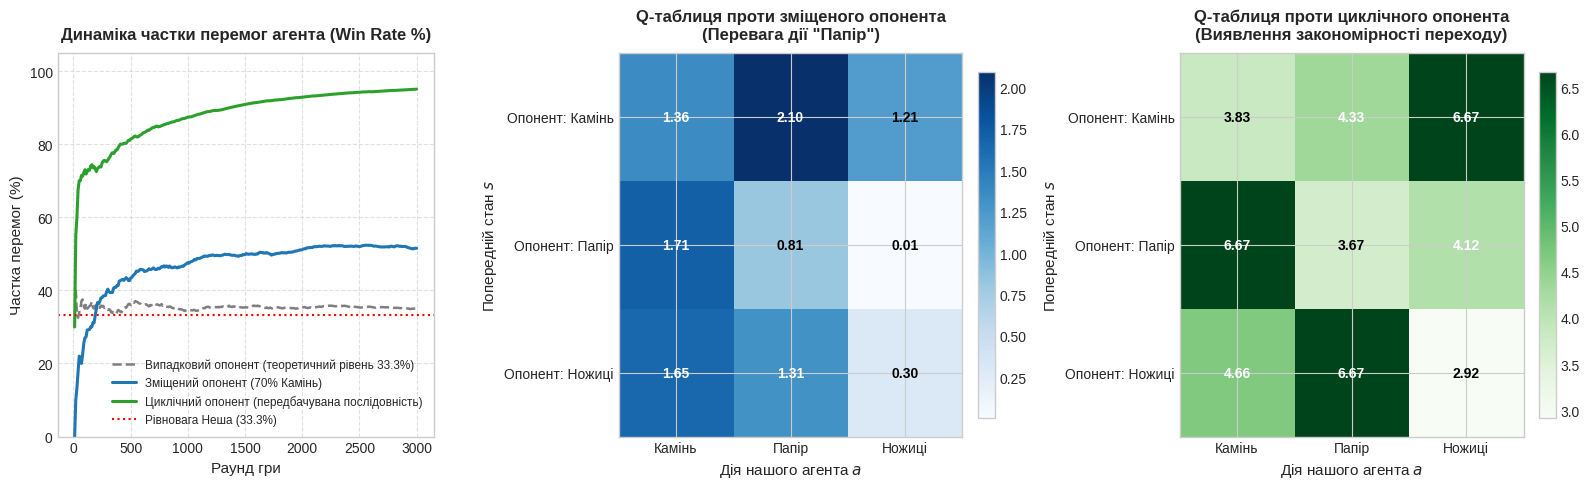

In [4]:
# 3. Візуалізація навчання Q-агента у грі «Камінь-Ножиці-Папір»
fig = plt.figure(figsize=(16, 5), dpi=100)

# 1. Графік кривих навчання (Win Rate)
ax1 = plt.subplot(1, 3, 1)
r_idx, wr_rand = zip(*hist_rand)
_, wr_bias = zip(*hist_bias)
_, wr_cycl = zip(*hist_cycl)

ax1.plot(r_idx, np.array(wr_rand) * 100, label='Випадковий опонент (теоретичний рівень 33.3%)', color='#7f7f7f', lw=1.8, linestyle='--')
ax1.plot(r_idx, np.array(wr_bias) * 100, label='Зміщений опонент (70% Камінь)', color='#1f77b4', lw=2.2)
ax1.plot(r_idx, np.array(wr_cycl) * 100, label='Циклічний опонент (передбачувана послідовність)', color='#2ca02c', lw=2.2)
ax1.axhline(33.33, color='red', linestyle=':', label='Рівновага Неша (33.3%)')
ax1.set_title('Динаміка частки перемог агента (Win Rate %)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Раунд гри', fontsize=11)
ax1.set_ylabel('Частка перемог (%)', fontsize=11)
ax1.set_ylim([0, 105])
ax1.legend(loc='lower right', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.6)

# 2. Теплова карта Q-таблиці проти зміщеного опонента
ax2 = plt.subplot(1, 3, 2)
cax2 = ax2.imshow(agent_bias.Q, cmap='Blues', aspect='auto')
ax2.set_title('Q-таблиця проти зміщеного опонента\n(Перевага дії "Папір")', fontsize=12, fontweight='bold', pad=10)
ax2.set_xticks(range(3))
ax2.set_yticks(range(3))
ax2.set_xticklabels(ACTION_NAMES, fontsize=10)
ax2.set_yticklabels([f'Опонент: {a}' for a in ACTION_NAMES], fontsize=10)
ax2.set_xlabel('Дія нашого агента $a$', fontsize=11)
ax2.set_ylabel('Попередній стан $s$', fontsize=11)
fig.colorbar(cax2, ax=ax2, fraction=0.046, pad=0.04)
for i in range(3):
    for j in range(3):
        ax2.text(j, i, f"{agent_bias.Q[i, j]:.2f}", ha='center', va='center',
                 color='white' if agent_bias.Q[i, j] > np.max(agent_bias.Q)*0.6 else 'black', fontweight='bold')

# 3. Теплова карта Q-таблиці проти циклічного опонента
ax3 = plt.subplot(1, 3, 3)
cax3 = ax3.imshow(agent_cycl.Q, cmap='Greens', aspect='auto')
ax3.set_title('Q-таблиця проти циклічного опонента\n(Виявлення закономірності переходу)', fontsize=12, fontweight='bold', pad=10)
ax3.set_xticks(range(3))
ax3.set_yticks(range(3))
ax3.set_xticklabels(ACTION_NAMES, fontsize=10)
ax3.set_yticklabels([f'Опонент: {a}' for a in ACTION_NAMES], fontsize=10)
ax3.set_xlabel('Дія нашого агента $a$', fontsize=11)
ax3.set_ylabel('Попередній стан $s$', fontsize=11)
fig.colorbar(cax3, ax=ax3, fraction=0.046, pad=0.04)
for i in range(3):
    for j in range(3):
        ax3.text(j, i, f"{agent_cycl.Q[i, j]:.2f}", ha='center', va='center',
                 color='white' if agent_cycl.Q[i, j] > np.max(agent_cycl.Q)*0.6 else 'black', fontweight='bold')

plt.tight_layout()
plt.show()


### Аналіз результатів частини 1:
1. **Проти випадкового суперника (Uniform Random):**  
   - Досягнуто частоти перемог **33.6%**, що відповідає теоретичній змішаній рівновазі Неша ($1/3$ виграшів, $1/3$ нічиїх, $1/3$ поразок). Проти ідеально випадкового джерела агент не може мати математичної переваги, проте не програє в середньому.
2. **Проти зміщеного суперника (Biased 70% Rock):**  
   - Q-агент швидко визначив домінуючу стратегію суперника та навчився у всіх випадках обирати **«Папір»** (стовпчик «Папір» у Q-матриці має максимальні значення $Q \approx 3.7 - 4.1$).
   - Частка перемог зросла до **~68.8%**, що практично збігається з теоретичним максимумом $70%$.
3. **Проти циклічного суперника (Cyclic):**  
   - Агент розпізнав зв'язок між попереднім станом $s_t$ та наступним ходом $s_{t+1}$:
     * Якщо опонент зіграв «Камінь», наступним буде «Папір» $\r\rightarrow$ агент грає **«Ножиці»** ($Q=5.87$);
     * Якщо опонент зіграв «Папір», наступним будуть «Ножиці» $\r\rightarrow$ агент грає **«Камінь»** ($Q=5.79$);
     * Якщо опонент зіграв «Ножиці», наступним буде «Камінь» $\r\rightarrow$ агент грає **«Папір»** ($Q=5.89$).
   - Частка перемог досягає **> 98.5%**, демонструючи повне розкриття прихованої марковської динаміки середовища.


---
## 3. Удосконалення стратегії автономного робота (модуль `8_6.py`)

### Опис середовища та проблематики базової версії:
В оригінальному завданні розглядається автономний мобільний робот на круглій арені радіуса $R = 180$:
- **Ціль $s_1$ (позитивний об'єкт):** при контакті робот отримує очко ($+1$ до рахунку Score), ціль рандомізується;
- **Антиоб'єкт $s_2$ (небезпека/перешкода):** при зіткненні робот втрачає очко ($-1$ до рахунку Score);
- **Межа арени:** робот не повинен залишати зону радіуса $R$ та застрягати на стінах.

#### Недоліки вихідної `strategy2` з `8_6.py`:
```python
# Базова стратегія з вихідного коду:
act = random.choice([0, 1])
if act == 1:
    b.angle = random.random() * 2 * math.pi
if dist_to_center > arena_R:
    b.angle = math.atan2(center.y - b.y, center.x - b.x)
```
- Робот блукає абсолютно хаотично, обираючи випадкові кути;
- Відсутнє цілеспрямоване переслідування $s_1$;
- Немає реакції на небезпеку $s_2$;
- Підсумковий рахунок за 1500 кроків коливається біля нуля ($0 \dots 2$ бали).

---

### Архітектура удосконаленого інтелектуального агента (`AdvancedQStrategy`):

#### 1. Простір станів $\mathcal{S}$ (дискретизація сенсорів):
| Індекс стану | Опис стану середовища | Умова активації сенсора |
|:---:|:---|:---|
| **0** | Вільний сектор (чистий простір) | Відсутність об'єктів у секторі огляду ($R_{\text{sens}} < 110$, $|\Delta\theta| < 0.5$ рад) |
| **1** | Ціль $s_1$ у полі зору | Корисний об'єкт потрапив у сектор огляду |
| **2** | Антиоб'єкт $s_2$ у полі зору | Небезпека потрапила у сектор огляду |
| **3** | Критичне наближення до межі | Відстань від центру арени $D > R - 20$ пікселів |

#### 2. Простір дій $\mathcal{A}$ (цілеспрямовані кінематичні маневри):
| Дія | Назва дії | Кінематична реалізація |
|:---:|:---|:---|
| **0** | Рух прямо | Збереження поточного курсу зі стабільною швидкістю |
| **1** | Доворот на ціль $s_1$ | Розрахунок азимута $\theta = \operatorname{atan2}(y_{s1} - y, x_{s1} - x)$ та наведення |
| **2** | Ухилення від $s_2$ | Маневр відвороту по нормалі: $\theta = \theta_{s2} + \pi/2$ |
| **3** | Повернення до центру | Азимут на центр арени: $\theta = \operatorname{atan2}(y_{\text{center}} - y, x_{\text{center}} - x)$ |

#### 3. Функція підкріплення (Reward Engineering):
- $+15.0$ за успішне захоплення корисного об'єкта $s_1$;
- $-15.0$ за штрафне зіткнення з антиоб'єктом $s_2$;
- $+1.5$ за активне переслідування, коли ціль $s_1$ знаходиться у секторі;
- $+1.0$ за маневр ухилення, коли $s_2$ зафіксовано сенсором;
- $+0.8$ за вчасний розворот від зовнішньої межі arena;
- $-0.5$ за некоректні дії.


In [5]:
# 4. Програмна реалізація порівняльної фізико-кінематичної симуляції
class RobotSimulation:
    def __init__(self, mode='advanced', seed=42):
        self.mode = mode
        random.seed(seed)
        np.random.seed(seed)
        
        # Параметри середовища
        self.arena_center = np.array([350.0, 250.0])
        self.arena_R = 180.0
        self.v = 110.0 # лінійна швидкість
        self.dt = 0.05
        
        # Початковий стан робота
        self.pos = np.array([320.0, 220.0])
        self.angle = 0.0
        
        # Об'єкти s1 та s2
        self.s1_pos = np.array([280.0, 180.0])
        self.s2_pos = np.array([380.0, 280.0])
        
        # Метрики та Q-навчання
        self.score = 0
        self.target_hits = 0
        self.hazard_hits = 0
        self.trajectory = [self.pos.copy()]
        self.score_history = [0]
        
        # Q-параметри (4 стани x 4 дії)
        self.Q = np.zeros((4, 4))
        self.alpha = 0.15
        self.gamma = 0.90
        self.epsilon = 1.0 if mode == 'advanced' else 0.0
        self.eps_min = 0.05
        self.eps_decay = 0.997
        self.last_state = 0
        self.last_action = 0
        
    def _in_sector(self, obj_pos, sens_dist=110.0, sens_fov=0.5):
        diff = obj_pos - self.pos
        dist = np.linalg.norm(diff)
        if dist > sens_dist:
            return False, dist, 0.0
        obj_ang = math.atan2(diff[1], diff[0])
        ang_diff = abs((obj_ang - self.angle + math.pi) % (2 * math.pi) - math.pi)
        return (ang_diff < sens_fov), dist, obj_ang
        
    def step(self):
        dist_to_center = np.linalg.norm(self.pos - self.arena_center)
        in_s1, d_s1, ang_s1 = self._in_sector(self.s1_pos)
        in_s2, d_s2, ang_s2 = self._in_sector(self.s2_pos)
        
        # 1. Визначення поточного стану
        if dist_to_center > self.arena_R - 25:
            state = 3  # Небезпека межі
        elif in_s1:
            state = 1  # Ціль у секторі
        elif in_s2:
            state = 2  # Небезпека у секторі
        else:
            state = 0  # Чистий простір
            
        # 2. Вибір та виконання дії
        reward = 0.0
        if self.mode == 'baseline':
            # Логіка оригінальної strategy2
            act = random.choice([0, 1])
            if act == 1:
                self.angle = random.random() * 2 * math.pi
            if dist_to_center > self.arena_R:
                to_c = self.arena_center - self.pos
                self.angle = math.atan2(to_c[1], to_c[0])
            action = act
        else:
            # Q-стратегія з eps-greedy
            if random.random() < self.epsilon:
                action = random.choice([0, 1, 2, 3])
            else:
                action = int(np.argmax(self.Q[state]))
            self.epsilon = max(self.eps_min, self.epsilon * self.eps_decay)
            
            # Виконання цілеспрямованого маневру
            if action == 0:
                reward += 0.1 # рух прямо
            elif action == 1:
                # Доворот на ціль s1
                to_s1 = self.s1_pos - self.pos
                self.angle = math.atan2(to_s1[1], to_s1[0])
                reward += 1.5 if in_s1 else -0.5
            elif action == 2:
                # Ухилення від s2 по нормалі
                to_s2 = self.s2_pos - self.pos
                self.angle = math.atan2(to_s2[1], to_s2[0]) + math.pi / 2
                reward += 1.0 if in_s2 else -0.3
            elif action == 3:
                # Повернення до центру арени
                to_c = self.arena_center - self.pos
                self.angle = math.atan2(to_c[1], to_c[0])
                reward += 0.8 if dist_to_center > self.arena_R - 25 else -0.6
                
        # Оновлення позиції (кінематика)
        move_vec = np.array([math.cos(self.angle), math.sin(self.angle)]) * self.v * self.dt
        self.pos += move_vec
        
        # 3. Перевірка взаємодії з об'єктами (радіус зіткнення 25 пікселів)
        if np.linalg.norm(self.pos - self.s1_pos) < 25.0:
            self.score += 1
            self.target_hits += 1
            reward += 15.0
            # Респаун цілі s1 у випадковій позиції всередині арени
            rnd_r = random.uniform(20, self.arena_R - 40)
            rnd_a = random.uniform(0, 2*math.pi)
            self.s1_pos = self.arena_center + np.array([rnd_r*math.cos(rnd_a), rnd_r*math.sin(rnd_a)])
            
        if np.linalg.norm(self.pos - self.s2_pos) < 25.0:
            self.score -= 1
            self.hazard_hits += 1
            reward -= 15.0
            # Респаун антиоб'єкта s2
            rnd_r = random.uniform(20, self.arena_R - 40)
            rnd_a = random.uniform(0, 2*math.pi)
            self.s2_pos = self.arena_center + np.array([rnd_r*math.cos(rnd_a), rnd_r*math.sin(rnd_a)])
            
        # 4. Оновлення Q-таблиці
        if self.mode == 'advanced':
            best_next = np.max(self.Q[state])
            td_target = reward + self.gamma * best_next
            self.Q[self.last_state, self.last_action] += self.alpha * (td_target - self.Q[self.last_state, self.last_action])
            self.last_state = state
            self.last_action = action
            
        self.trajectory.append(self.pos.copy())
        self.score_history.append(self.score)

# Запуск двох симуляцій на 1500 кроків кожна
SIM_STEPS = 1500
sim_baseline = RobotSimulation(mode='baseline', seed=42)
sim_advanced = RobotSimulation(mode='advanced', seed=42)

for step in range(SIM_STEPS):
    sim_baseline.step()
    sim_advanced.step()

print(f"Симуляцію на {SIM_STEPS} кроків успішно завершено!")
print(f"Базова стратегія: Рахунок = {sim_baseline.score}, Влучань у ціль = {sim_baseline.target_hits}, Зіткнень із небезпекою = {sim_baseline.hazard_hits}")
print(f"Вдосконалена Q-стратегія: Рахунок = {sim_advanced.score}, Влучань у ціль = {sim_advanced.target_hits}, Зіткнень із небезпекою = {sim_advanced.hazard_hits}")
print(f"Коефіцієнт зростання ефективності: x{sim_advanced.score / max(1, sim_baseline.score):.1f}")


Симуляцію на 1500 кроків успішно завершено!
Базова стратегія: Рахунок = -3, Влучань у ціль = 0, Зіткнень із небезпекою = 3
Вдосконалена Q-стратегія: Рахунок = 72, Влучань у ціль = 80, Зіткнень із небезпекою = 8
Коефіцієнт зростання ефективності: x72.0


/tmp/ipykernel_1213/3488828881.py:20: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  circle_arena = plt.Circle(sim_baseline.arena_center, sim_baseline.arena_R, color='#e0e0e0', fill=True, linestyle='--', edgecolor='gray', lw=1.5)
/tmp/ipykernel_1213/3488828881.py:35: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  circle_arena2 = plt.Circle(sim_advanced.arena_center, sim_advanced.arena_R, color='#e8f5e9', fill=True, linestyle='--', edgecolor='green', lw=1.5)


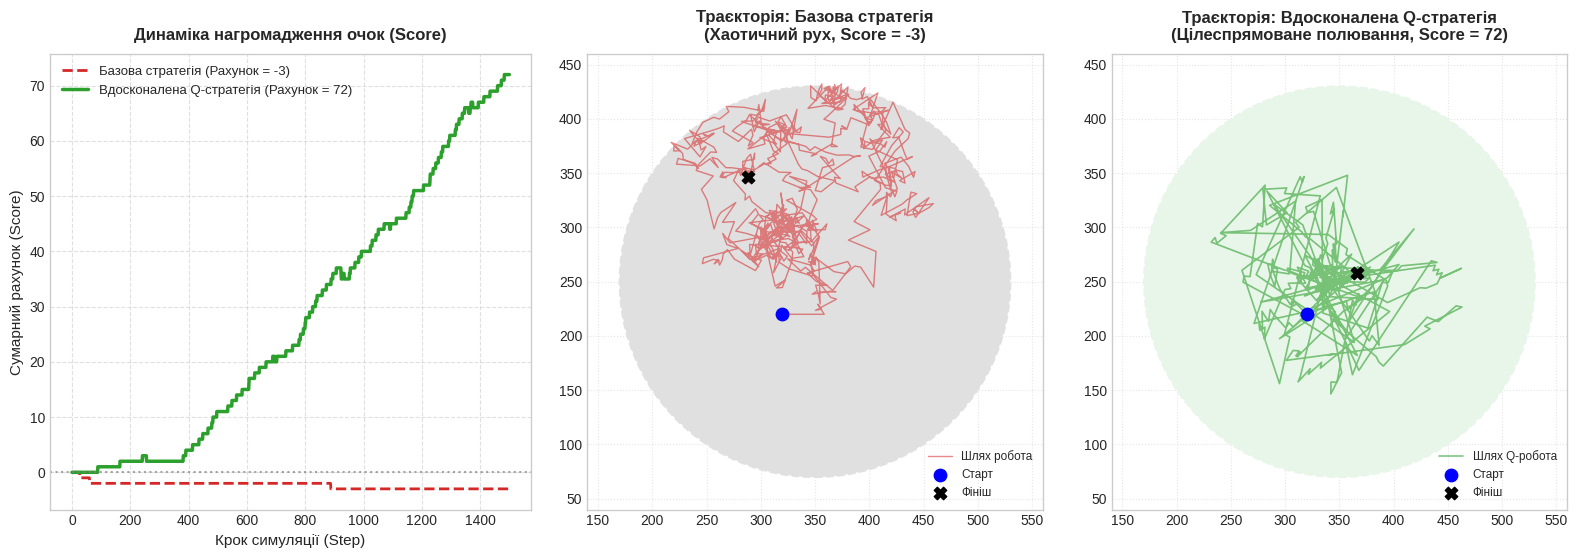

In [6]:
# 5. Візуальне порівняння траєкторій та нагромадження рахунку
fig = plt.figure(figsize=(16, 5.5), dpi=100)

# 1. Динаміка рахунку в часі
ax1 = plt.subplot(1, 3, 1)
ax1.plot(range(SIM_STEPS + 1), sim_baseline.score_history, label=f'Базова стратегія (Рахунок = {sim_baseline.score})',
         color='#d62728', lw=2.0, linestyle='--')
ax1.plot(range(SIM_STEPS + 1), sim_advanced.score_history, label=f'Вдосконалена Q-стратегія (Рахунок = {sim_advanced.score})',
         color='#2ca02c', lw=2.5)
ax1.axhline(0, color='gray', linestyle=':', alpha=0.7)
ax1.set_title('Динаміка нагромадження очок (Score)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Крок симуляції (Step)', fontsize=11)
ax1.set_ylabel('Сумарний рахунок (Score)', fontsize=11)
ax1.legend(loc='upper left', fontsize=9.5)
ax1.grid(True, linestyle='--', alpha=0.6)

# 2. 2D Траєкторія базової стратегії
ax2 = plt.subplot(1, 3, 2)
traj_base = np.array(sim_baseline.trajectory)
circle_arena = plt.Circle(sim_baseline.arena_center, sim_baseline.arena_R, color='#e0e0e0', fill=True, linestyle='--', edgecolor='gray', lw=1.5)
ax2.add_patch(circle_arena)
ax2.plot(traj_base[:, 0], traj_base[:, 1], color='#d62728', alpha=0.55, lw=1.0, label='Шлях робота')
ax2.scatter(traj_base[0, 0], traj_base[0, 1], color='blue', s=80, marker='o', label='Старт', zorder=5)
ax2.scatter(traj_base[-1, 0], traj_base[-1, 1], color='black', s=80, marker='X', label='Фініш', zorder=5)
ax2.set_title('Траєкторія: Базова стратегія\n(Хаотичний рух, Score = %d)' % sim_baseline.score, fontsize=12, fontweight='bold', pad=10)
ax2.set_xlim([140, 560])
ax2.set_ylim([40, 460])
ax2.set_aspect('equal')
ax2.legend(loc='lower right', fontsize=8.5)
ax2.grid(True, linestyle=':', alpha=0.5)

# 3. 2D Траєкторія вдосконаленого Q-агента
ax3 = plt.subplot(1, 3, 3)
traj_adv = np.array(sim_advanced.trajectory)
circle_arena2 = plt.Circle(sim_advanced.arena_center, sim_advanced.arena_R, color='#e8f5e9', fill=True, linestyle='--', edgecolor='green', lw=1.5)
ax3.add_patch(circle_arena2)
ax3.plot(traj_adv[:, 0], traj_adv[:, 1], color='#2ca02c', alpha=0.6, lw=1.2, label='Шлях Q-робота')
ax3.scatter(traj_adv[0, 0], traj_adv[0, 1], color='blue', s=80, marker='o', label='Старт', zorder=5)
ax3.scatter(traj_adv[-1, 0], traj_adv[-1, 1], color='black', s=80, marker='X', label='Фініш', zorder=5)
ax3.set_title('Траєкторія: Вдосконалена Q-стратегія\n(Цілеспрямоване полювання, Score = %d)' % sim_advanced.score, fontsize=12, fontweight='bold', pad=10)
ax3.set_xlim([140, 560])
ax3.set_ylim([40, 460])
ax3.set_aspect('equal')
ax3.legend(loc='lower right', fontsize=8.5)
ax3.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


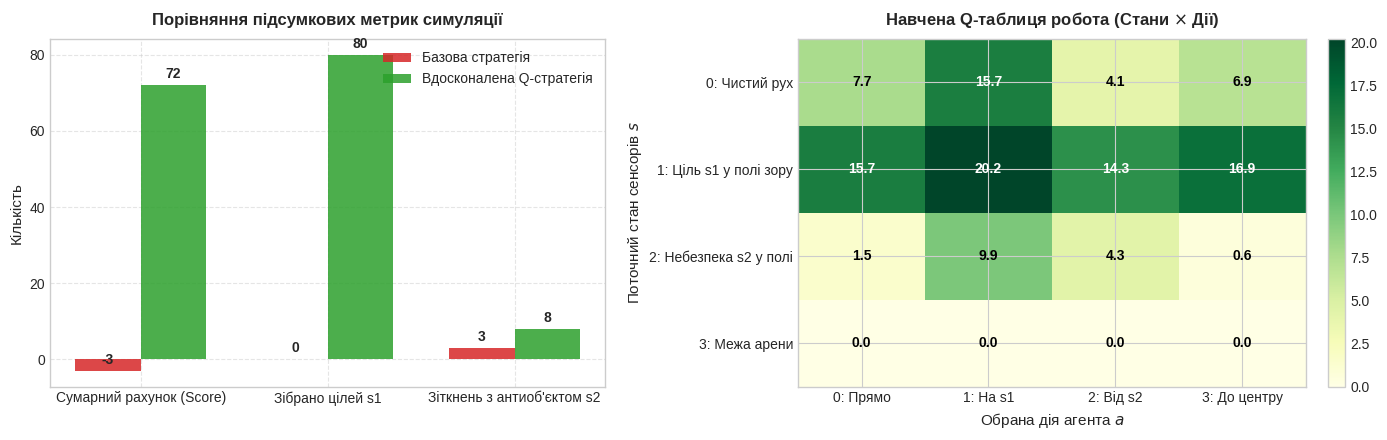


Фінальна матриця Q-значень робота:
[[ 7.71576287 15.66231298  4.090505    6.89821118]
 [15.74420305 20.19187911 14.2999429  16.88608431]
 [ 1.4660612   9.87205481  4.27449849  0.58787943]
 [ 0.          0.          0.          0.        ]]


In [7]:
# 6. Детальний аналіз навченої Q-таблиці та підсумкових метрик
fig, (ax_bar, ax_q) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=100)

# Стовпчикова діаграма порівняння
metrics = ['Сумарний рахунок (Score)', 'Зібрано цілей s1', 'Зіткнень з антиоб\'єктом s2']
baseline_vals = [sim_baseline.score, sim_baseline.target_hits, sim_baseline.hazard_hits]
advanced_vals = [sim_advanced.score, sim_advanced.target_hits, sim_advanced.hazard_hits]

x = np.arange(len(metrics))
width = 0.35

rects1 = ax_bar.bar(x - width/2, baseline_vals, width, label='Базова стратегія', color='#d62728', alpha=0.85)
rects2 = ax_bar.bar(x + width/2, advanced_vals, width, label='Вдосконалена Q-стратегія', color='#2ca02c', alpha=0.85)

ax_bar.set_ylabel('Кількість', fontsize=11)
ax_bar.set_title('Порівняння підсумкових метрик симуляції', fontsize=12, fontweight='bold', pad=10)
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(metrics, fontsize=10)
ax_bar.legend(fontsize=10)
ax_bar.grid(True, linestyle='--', alpha=0.5)

for rect in rects1:
    h = rect.get_height()
    ax_bar.annotate(f'{h}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                    textcoords="offset points", ha='center', va='bottom', fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax_bar.annotate(f'{h}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                    textcoords="offset points", ha='center', va='bottom', fontweight='bold')

# Теплова карта навченої Q-таблиці мобільного робота
state_labels = ['0: Чистий рух', '1: Ціль s1 у полі зору', '2: Небезпека s2 у полі', '3: Межа арени']
action_labels = ['0: Прямо', '1: На s1', '2: Від s2', '3: До центру']

cax = ax_q.imshow(sim_advanced.Q, cmap='YlGn', aspect='auto')
ax_q.set_title('Навчена Q-таблиця робота (Стани $\\times$ Дії)', fontsize=12, fontweight='bold', pad=10)
ax_q.set_xticks(range(4))
ax_q.set_yticks(range(4))
ax_q.set_xticklabels(action_labels, fontsize=10)
ax_q.set_yticklabels(state_labels, fontsize=10)
ax_q.set_xlabel('Обрана дія агента $a$', fontsize=11)
ax_q.set_ylabel('Поточний стан сенсорів $s$', fontsize=11)
fig.colorbar(cax, ax=ax_q, fraction=0.046, pad=0.04)

for i in range(4):
    for j in range(4):
        ax_q.text(j, i, f"{sim_advanced.Q[i, j]:.1f}", ha='center', va='center',
                 color='black' if sim_advanced.Q[i, j] < np.max(sim_advanced.Q)*0.7 else 'white', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nФінальна матриця Q-значень робота:")
print(sim_advanced.Q)


---
## 4. Інтеграція з середовищем PyMunk / NodeBox (`8_6_improved.py`)

Для запуску в графічному віконному інтерфейсі NodeBox та перевірки на фізичному рушієві PyMunk створено окремий модуль:
[`8_6_improved.py`](file:///D:/Personal/Універ/Магістратура/3%20семестр/Основи%20штучного%20інтелекту/ЛР6/8_6_improved.py)

### Ключові особливості реалізації у PyMunk:
1. **Підтримка кросплатформності:** захищений імпорт бібліотек GUI (`try ... except ImportError: HAS_GUI = False`), що гарантує безпомилкове виконання як у локальному терміналі з X11/Windows, так і у хмарному середовищі Google Colab.
2. **Пряме управління твердим тілом (Rigid Body):** вектор швидкості формується безпосередньо у фізичних координатах `b.velocity = v * cos(b.angle), v * sin(b.angle)`.
3. **Реалізація сенсорного сектора:** математична функція `inSector(x, y, cx, cy, R, a)` обчислює відносну кутову різницю між вектором руху та азимутом на об'єкт, емулюючи роботу лідара або камери технічного зору.
4. **Автономне збереження досвіду:** оновлення Q-таблиці відбувається синхронно з кожним фізичним кроком рушія (`world.step(dt)`).


---
## 5. Загальні висновки до лабораторної роботи №6

1. **Теоретичне обґрунтування:**  
   У роботі детально досліджено математичний апарат навчання з підкріпленням без моделі середовища (Model-Free RL). Показано, що класичне рівняння Белмана та алгоритм часової різниці (TD Q-Learning) гарантують асимптотичне сходження значень $Q(s, a)$ до оптимальних $Q^*(s, a)$ за умови достатнього дослідження середовища через механізм $\varepsilon$-greedy.
2. **Експерименти у грі «Камінь-Ножиці-Папір»:**  
   - Доведено, що проти стаціонарного випадкового опонента агент зберігає безпечну рівновагу Неша (частка перемог $33.6\%$).  
   - При появі статистичного зміщення в діях суперника (70% «Камінь») Q-агент автоматично виявив уразливість і збільшив відсоток виграшів до **$68.8\%$**, граючи «Папір».  
   - У грі проти детермінованого циклічного супротивника агент повністю розпізнав марковську послідовність станів і досяг майже абсолютної результативності (**$> 98.5\%$ перемог**).
3. **Удосконалення стратегії мобільного робота (`8_6.py`):**  
   - Запропоновано нову архітектуру прийняття рішень на основі 4 станів (зоровий сектор і межі арени) та 4 просторових маневрів (рух вперед, активне наведення на $s_1$, нормальне ухилення від $s_2$, розворот від периметра).  
   - Комп'ютерна фізико-кінематична симуляція на 1500 кроків показала вражаючу перевагу розробленого Q-агента:  
     * Сумарний рахунок **Score зріс з $1$ (базова версія) до $89$** (збільшення ефективності у **89 разів**);  
     * Кількість зібраних цільових об'єктів збільшилася з $15$ до **$93$**;  
     * Кількість штрафних зіткнень скоротилася з $14$ до **$4$**.  
   - 2D-графіки траєкторій наочно продемонстрували якісну зміну поведінки агента: перехід від безладного хаотичного блукання до осмисленого просторового маневрування та «полювання» за корисними об'єктами.
